# Análisis del dataset de empleados. Daniel

## Descripción del dataset

El archivo `dataset.csv` contiene información de empleados activos y combina datos de las tablas `HumanResources.Employee`, `Department`, `EmployeeDepartmentHistory`, `EmployeePayHistory` y `Shift` de SQL Server. La preparación y exportación inicial se realiza en `Connection.py`.

## Objetivo

Cargar el CSV generado por el proyecto, preparar sus tipos de datos, verificar su estructura e integridad y realizar el análisis exploratorio (EDA): estructura y anomalías, estadística descriptiva y análisis por segmentos (`JobTitle`, `Departamento`, `Turno`).

## Variables del dataset

| Variable | Descripción |
|---|---|
| `BusinessEntityID` | Identificador del empleado. |
| `JobTitle` | Cargo del empleado. |
| `BirthDate` | Fecha de nacimiento. |
| `Gender` | Género registrado. |
| `MaritalStatus` | Estado civil registrado. |
| `HireDate` | Fecha de contratación. |
| `SalariedFlag` | Indicador de salario fijo. |
| `VacationHours` | Horas de vacaciones disponibles. |
| `SickLeaveHours` | Horas de licencia por enfermedad disponibles. |
| `Departamento` | Nombre del departamento actual. |
| `GrupoDepartamento` | Grupo al que pertenece el departamento. |
| `Turno` | Nombre del turno actual. |
| `Tarifa` | Tarifa de pago más reciente disponible. |
| `PayFrequency` | Frecuencia de pago registrada. |

## Índice

A. [Librerías](#A.-Librerías)  
B. [Carga de datos y preparación del dataset](#B.-Carga-de-datos-y-preparación-del-dataset)  
C. [Librerías para el EDA](#C.-Librerías-para-el-EDA)  
D. [1.C Estructura y anomalías](#1.C-Estructura-del-dataset-y-análisis-de-anomalías)  
E. [2. Análisis descriptivo](#2.-Análisis-descriptivo) (2.A histogramas y frecuencias · 2.B tendencia central · 2.C separatrices y outliers IQR · 2.D dispersión)  
F. [3. Análisis por segmentos](#3.-Análisis-por-segmentos) (3.A `JobTitle` · 3.B `Departamento` · 3.C `Turno` · 3.D cruce)  
G. [Conclusión general del EDA](#Conclusión-general-del-EDA)

> **Antes de ejecutar:** instala las dependencias con `pip install -r requirements.txt`. Si `dataset.csv` no existe, configura las variables `DB_SERVER`, `DB_NAME`, `DB_USER` y `DB_PASSWORD` en el archivo local `.env` (no compartas ese archivo) y ejecuta `Connection.py` para generarlo. El notebook no contiene credenciales ni se conecta directamente a la base de datos.

## A. Librerías

- **pandas**: lectura, selección y preparación tabular del CSV.
- **SQLAlchemy**: creación del motor de conexión en `Connection.py`.
- **pyodbc**: controlador Python utilizado por SQLAlchemy para conectarse a SQL Server. También se debe instalar el controlador ODBC de SQL Server compatible en el equipo.

Las dependencias están declaradas en `requirements.txt`. La siguiente celda muestra las versiones instaladas sin imprimir información de conexión.

In [ ]:
from pathlib import Path

import pandas as pd
import pyodbc
import sqlalchemy

print(f"pandas: {pd.__version__}")
print(f"SQLAlchemy: {sqlalchemy.__version__}")
print(f"pyodbc: {pyodbc.version}")

## B. Carga de datos y preparación del dataset

`Connection.py` consulta las tablas de SQL Server, conserva empleados activos, incorpora departamento, turno y tarifa más reciente, valida el resultado y lo guarda como `dataset.csv`. Aquí se carga ese resultado para mantener una sola implementación del proceso de extracción y joins.

Las fechas se interpretan como fechas y `Tarifa` se convierte a tipo numérico. Si el CSV todavía no se ha generado, la celda indica cómo crearlo.

In [2]:
dataset_path = Path("dataset.csv")
if not dataset_path.is_file():
    raise FileNotFoundError(
        "No se encontró dataset.csv. Configura el archivo .env y ejecuta "
        "Connection.py para extraer y preparar los datos desde SQL Server."
    )

columnas_esperadas = [
    "BusinessEntityID", "JobTitle", "BirthDate", "Gender", "MaritalStatus",
    "HireDate", "SalariedFlag", "VacationHours", "SickLeaveHours",
    "Departamento", "GrupoDepartamento", "Turno", "Tarifa", "PayFrequency",
]

dataset = pd.read_csv(
    dataset_path,
    encoding="utf-8-sig",
    parse_dates=["BirthDate", "HireDate"],
)

columnas_faltantes = sorted(set(columnas_esperadas) - set(dataset.columns))
if columnas_faltantes:
    raise ValueError(f"Faltan columnas requeridas en el CSV: {columnas_faltantes}")

dataset = dataset[columnas_esperadas].copy()
dataset["Tarifa"] = pd.to_numeric(dataset["Tarifa"], errors="raise")

print(f"Filas: {dataset.shape[0]:,}")
print(f"Columnas: {dataset.shape[1]}")
dataset.head()

Filas: 290
Columnas: 14


,BusinessEntityID,JobTitle,BirthDate,Gender,MaritalStatus,HireDate,SalariedFlag,VacationHours,SickLeaveHours,Departamento,GrupoDepartamento,Turno,Tarifa,PayFrequency
0,1,Chief Executive Officer,1969-01-29,M,S,2009-01-14,True,99,69,Executive,Executive General and Administration,Day,125.5000,2
1,2,Vice President of Engineering,1971-08-01,F,S,2008-01-31,True,1,20,Engineering,Research and Development,Day,63.4615,2
2,3,Engineering Manager,1974-11-12,M,M,2007-11-11,True,2,21,Engineering,Research and Development,Day,43.2692,2
3,4,Senior Tool Designer,1974-12-23,M,S,2007-12-05,False,48,80,Tool Design,Research and Development,Day,29.8462,2
4,5,Design Engineer,1952-09-27,F,M,2008-01-06,True,5,22,Engineering,Research and Development,Day,32.6923,2


### Verificación de integridad

Se comprueba que el identificador sea único y que no haya valores nulos. Si alguna condición no se cumple, la celda informa del problema en lugar de dar por válida la preparación.

In [3]:
duplicados = int(dataset["BusinessEntityID"].duplicated().sum())
nulos_por_columna = dataset.isna().sum()

if duplicados:
    raise ValueError(f"Se encontraron {duplicados} identificadores de empleado duplicados.")
if nulos_por_columna.any():
    raise ValueError(f"Se encontraron valores nulos:\n{nulos_por_columna[nulos_por_columna > 0]}")

print("Validación correcta: IDs únicos y sin valores nulos.")
print("Tipos de datos:")
display(dataset.dtypes.to_frame(name="Tipo"))
print("Resumen numérico:")
display(dataset.describe(include="all").transpose())

Validación correcta: IDs únicos y sin valores nulos.
Tipos de datos:


,Tipo
BusinessEntityID,int64
JobTitle,str
BirthDate,datetime64[us]
Gender,str
MaritalStatus,str
HireDate,datetime64[us]
SalariedFlag,bool
VacationHours,int64
SickLeaveHours,int64
Departamento,str


Resumen numérico:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
BusinessEntityID,290.0,NaN,NaN,NaN,145.5,1.0,73.25,145.5,217.75,290.0,83.860002
JobTitle,290,67,Production Technician - WC60,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BirthDate,290,NaN,NaN,NaN,1978-07-04 12:24:49.655172,1951-10-17 00:00:00,1973-09-21 18:00:00,1978-10-19 12:00:00,1986-05-27 12:00:00,1991-05-31 00:00:00,NaN
Gender,290,2,M,206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaritalStatus,290,2,M,146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HireDate,290,NaN,NaN,NaN,2009-05-19 05:57:31.034482,2006-06-30 00:00:00,2008-12-26 06:00:00,2009-02-02 00:00:00,2009-10-09 18:00:00,2013-05-30 00:00:00,NaN
SalariedFlag,290,2,False,238,NaN,NaN,NaN,NaN,NaN,NaN,NaN
VacationHours,290.0,NaN,NaN,NaN,50.613793,0.0,26.25,51.0,75.0,99.0,28.786215
SickLeaveHours,290.0,NaN,NaN,NaN,45.306897,20.0,33.0,46.0,58.0,80.0,14.540444
Departamento,290,16,Production,179,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## C. Librerías para el EDA

Se agregan **numpy**, **matplotlib** y **seaborn** para cálculos y visualizaciones. Las secciones siguientes reutilizan el DataFrame `dataset` cargado y validado en la sección B (ejecuta el notebook en orden).

In [4]:
import textwrap

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1.C Estructura del dataset y análisis de anomalías

Se revisan dimensiones, tipos de datos, valores nulos y duplicados (por fila completa y por identificador), además de algunas reglas de coherencia del negocio (tarifas positivas, fecha de contratación posterior al nacimiento, categorías con espacios sobrantes).

In [5]:
filas, columnas = dataset.shape
print(f"Estructura: {filas:,} filas × {columnas} columnas\n")

estructura = pd.DataFrame({
    "Tipo": dataset.dtypes.astype(str),
    "No nulos": dataset.notna().sum(),
    "Nulos": dataset.isna().sum(),
    "% nulos": dataset.isna().mean() * 100,
    "Valores únicos": dataset.nunique(),
})
display(estructura)

Estructura: 290 filas × 14 columnas



,Tipo,No nulos,Nulos,% nulos,Valores únicos
BusinessEntityID,int64,290,0,0.00,290
JobTitle,str,290,0,0.00,67
BirthDate,datetime64[us],290,0,0.00,275
Gender,str,290,0,0.00,2
MaritalStatus,str,290,0,0.00,2
HireDate,datetime64[us],290,0,0.00,164
SalariedFlag,bool,290,0,0.00,2
VacationHours,int64,290,0,0.00,100
SickLeaveHours,int64,290,0,0.00,51
Departamento,str,290,0,0.00,16


In [6]:
# --- Duplicados
dup_filas = int(dataset.duplicated().sum())
dup_id = int(dataset["BusinessEntityID"].duplicated().sum())
dup_sin_id = int(dataset.drop(columns="BusinessEntityID").duplicated().sum())
print(f"Filas completamente duplicadas ......... {dup_filas}")
print(f"IDs de empleado duplicados ............. {dup_id}")
print(f"Filas iguales ignorando el ID .......... {dup_sin_id}  (empleados con idéntico perfil, no necesariamente error)")

# --- Reglas de coherencia
edad_contratacion = (dataset["HireDate"] - dataset["BirthDate"]).dt.days / 365.25
chequeos = {
    "Tarifa <= 0": int((dataset["Tarifa"] <= 0).sum()),
    "Horas de vacaciones negativas": int((dataset["VacationHours"] < 0).sum()),
    "Horas de enfermedad negativas": int((dataset["SickLeaveHours"] < 0).sum()),
    "Contratado antes de los 16 años": int((edad_contratacion < 16).sum()),
    "HireDate anterior a BirthDate": int((dataset["HireDate"] < dataset["BirthDate"]).sum()),
}
cols_texto = dataset.select_dtypes(include=["object", "string"]).columns
chequeos["Textos con espacios sobrantes"] = int(sum((dataset[c] != dataset[c].str.strip()).sum() for c in cols_texto))
display(pd.Series(chequeos, name="Registros afectados").to_frame())

print("Rango de fechas:")
print(f"  BirthDate: {dataset['BirthDate'].min():%Y-%m-%d} → {dataset['BirthDate'].max():%Y-%m-%d}")
print(f"  HireDate : {dataset['HireDate'].min():%Y-%m-%d} → {dataset['HireDate'].max():%Y-%m-%d}")

Filas completamente duplicadas ......... 0
IDs de empleado duplicados ............. 0
Filas iguales ignorando el ID .......... 0  (empleados con idéntico perfil, no necesariamente error)


,Registros afectados
Tarifa <= 0,0
Horas de vacaciones negativas,0
Horas de enfermedad negativas,0
Contratado antes de los 16 años,0
HireDate anterior a BirthDate,0
Textos con espacios sobrantes,0


Rango de fechas:
  BirthDate: 1951-10-17 → 1991-05-31
  HireDate : 2006-06-30 → 2013-05-30


### Conclusiones 1.C — Estructura y anomalías

- **Estructura:** 290 empleados activos × 14 variables: 4 numéricas (`BusinessEntityID`, `VacationHours`, `SickLeaveHours`, `Tarifa`) más `PayFrequency` codificada como número, 2 fechas (`BirthDate`, `HireDate`), 1 booleana (`SalariedFlag`) y 6 de texto (`JobTitle`, `Gender`, `MaritalStatus`, `Departamento`, `GrupoDepartamento`, `Turno`). Los tipos son los esperados tras la carga.
- **Nulos:** 0 en todas las columnas (coherente con la validación de `Connection.py`, que descarta cualquier nulo tras los joins).
- **Duplicados:** 0 filas duplicadas, 0 IDs repetidos y 0 perfiles idénticos ignorando el ID.
- **Coherencia:** no hay tarifas ≤ 0, horas negativas, contrataciones antes del nacimiento (ni antes de los 16 años) ni textos con espacios sobrantes. Las contrataciones van de 2006 a 2013.
- **Observación:** `PayFrequency` (1/2) y `SalariedFlag` son numéricas/booleanas solo por codificación; se tratan como categóricas en el análisis.

**Conclusión:** el dataset es íntegro y no requiere imputaciones ni eliminación de registros; puede pasar directamente al análisis descriptivo.

## 2. Análisis descriptivo

**Clasificación de variables usada en esta sección**

- **Numéricas continuas/discretas:** `VacationHours`, `SickLeaveHours`, `Tarifa`.
- **Categóricas:** `JobTitle`, `Departamento`, `GrupoDepartamento`, `Turno`, `Gender`, `MaritalStatus`, y las binarias/codificadas `SalariedFlag` y `PayFrequency` (1 = mensual, 2 = quincenal según el esquema de AdventureWorks).
- **Excluidas:** `BusinessEntityID` es un identificador (promediarlo no tiene sentido) y las fechas se tratan aparte.

In [7]:
num_cols = ["VacationHours", "SickLeaveHours", "Tarifa"]
cat_bajas = ["Gender", "MaritalStatus", "SalariedFlag", "PayFrequency", "Turno", "GrupoDepartamento"]
cat_altas = ["Departamento", "JobTitle"]   # muchas categorías → barras horizontales

### 2.A Histogramas y gráficos de frecuencia

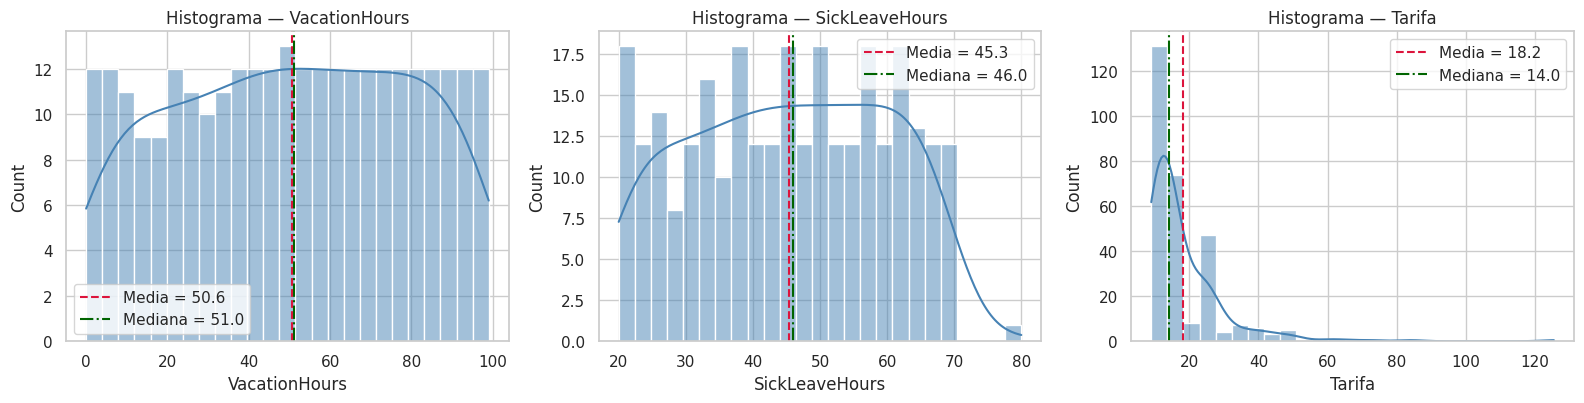

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, num_cols):
    sns.histplot(dataset[col], bins=25, kde=True, ax=ax, color="steelblue")
    ax.axvline(dataset[col].mean(), color="crimson", ls="--", label=f"Media = {dataset[col].mean():.1f}")
    ax.axvline(dataset[col].median(), color="darkgreen", ls="-.", label=f"Mediana = {dataset[col].median():.1f}")
    ax.set_title(f"Histograma — {col}")
    ax.legend()
plt.tight_layout()
plt.show()

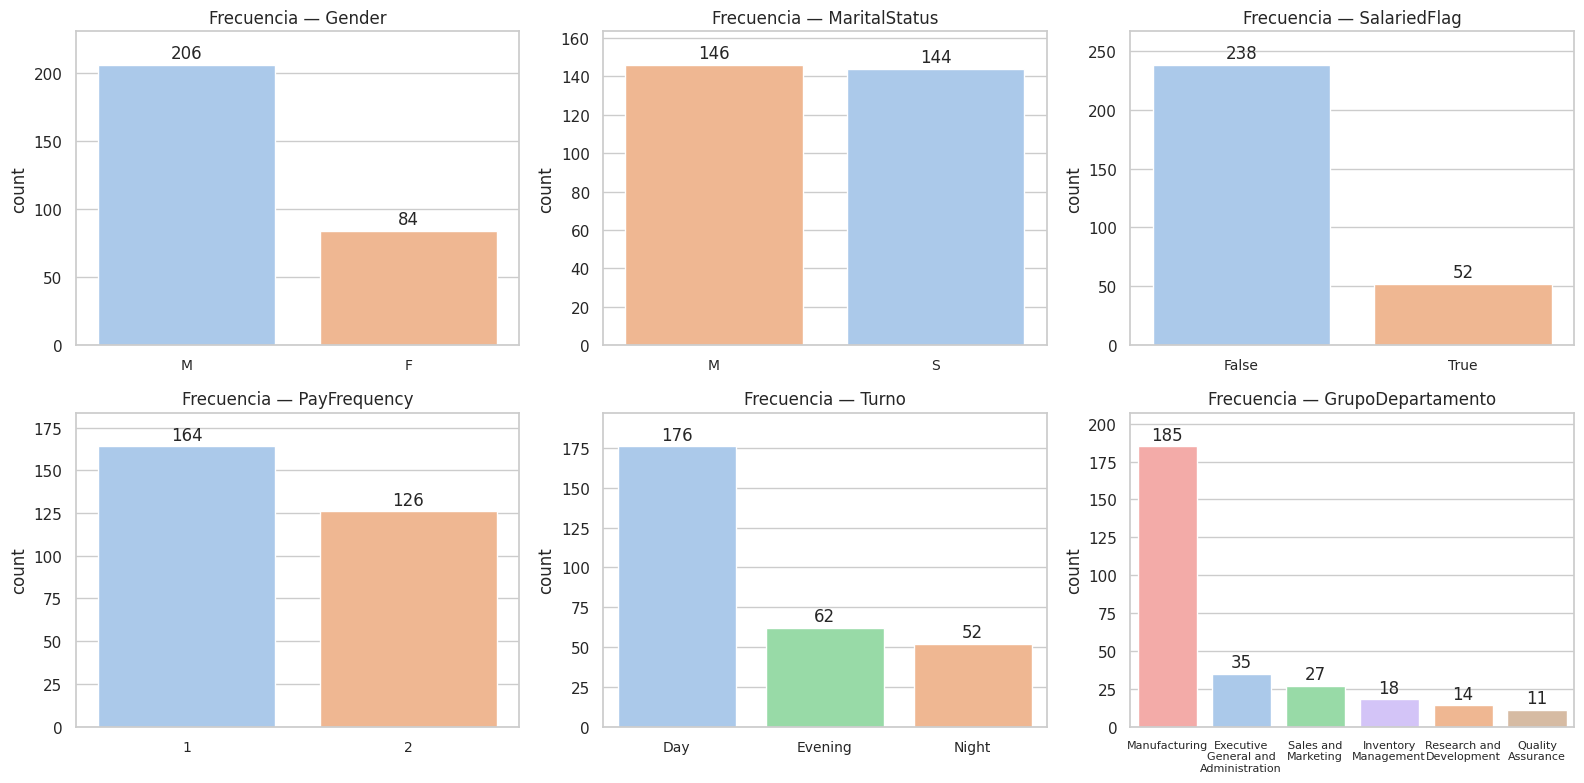

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cat_bajas):
    orden = dataset[col].value_counts().index
    sns.countplot(data=dataset, x=col, order=orden, hue=col, legend=False, palette="pastel", ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, padding=2)
    ax.set_title(f"Frecuencia — {col}")
    ax.set_xlabel("")
    ax.margins(y=0.12)
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels([textwrap.fill(t.get_text(), 14) for t in ax.get_xticklabels()], fontsize=8 if col == "GrupoDepartamento" else 10)
plt.tight_layout()
plt.show()

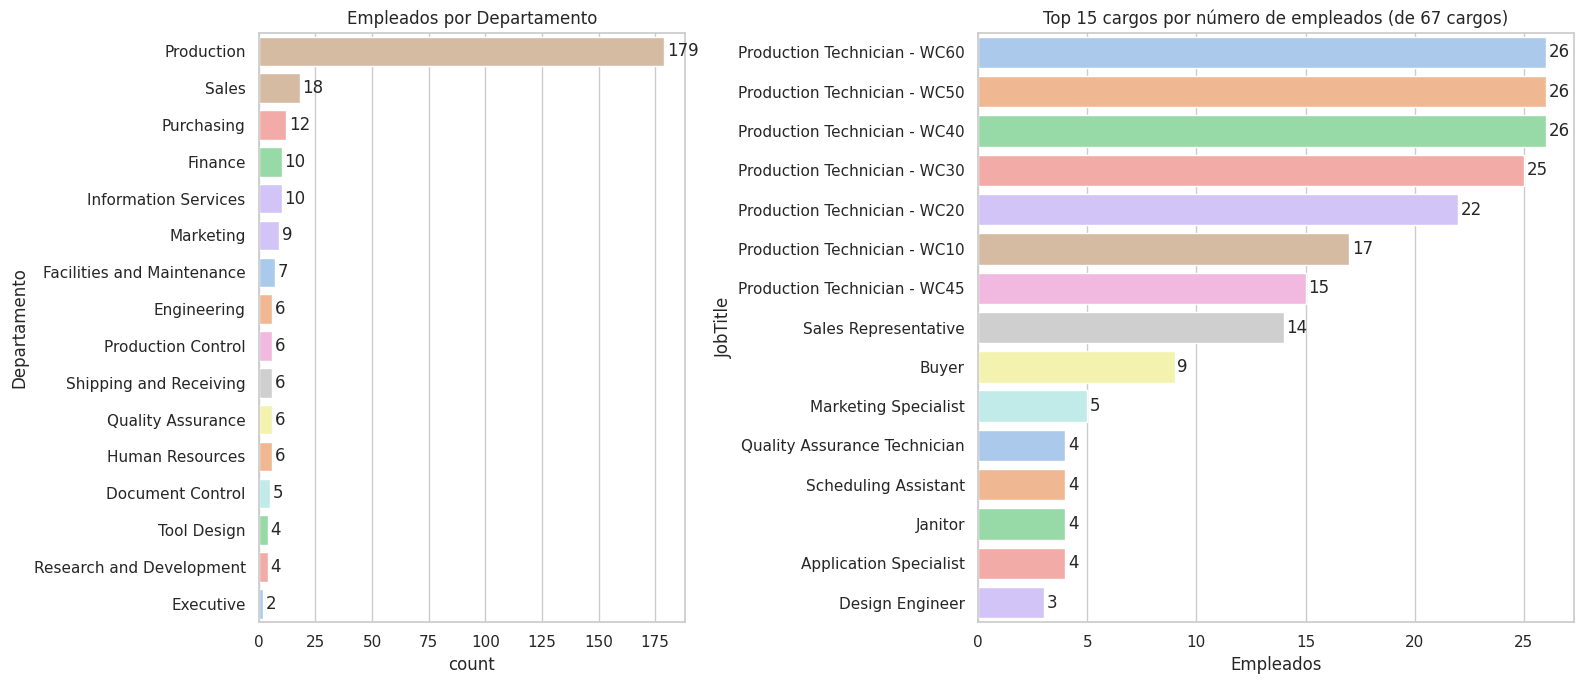

Frecuencias relativas (%):


Turno,Day,Evening,Night
Turno,,,
%,60.70,21.40,17.90


GrupoDepartamento,Manufacturing,Executive General and Administration,Sales and Marketing,Inventory Management,Research and Development,Quality Assurance
GrupoDepartamento,,,,,,
%,63.80,12.10,9.30,6.20,4.80,3.80


Gender,M,F
Gender,,
%,71.00,29.00


MaritalStatus,M,S
MaritalStatus,,
%,50.30,49.70


SalariedFlag,False,True
SalariedFlag,,
%,82.10,17.90


PayFrequency,1,2
PayFrequency,,
%,56.60,43.40


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.4]})

orden_dep = dataset["Departamento"].value_counts().index
sns.countplot(data=dataset, y="Departamento", order=orden_dep, hue="Departamento", legend=False, palette="pastel", ax=axes[0])
axes[0].set_title("Empleados por Departamento")

top_jobs = dataset["JobTitle"].value_counts().head(15)
sns.barplot(x=top_jobs.values, y=top_jobs.index, hue=top_jobs.index, legend=False, palette="pastel", ax=axes[1])
axes[1].set_title(f"Top 15 cargos por número de empleados (de {dataset['JobTitle'].nunique()} cargos)")
axes[1].set_xlabel("Empleados")
for ax in axes:
    for cont in ax.containers:
        ax.bar_label(cont, padding=2)
plt.tight_layout()
plt.show()

print("Frecuencias relativas (%):")
for col in ["Turno", "GrupoDepartamento", "Gender", "MaritalStatus", "SalariedFlag", "PayFrequency"]:
    display((dataset[col].value_counts(normalize=True) * 100).round(1).to_frame("%").T.rename_axis(col))

### 2.B Medidas de tendencia central (media, mediana, moda)

In [11]:
def moda(s):
    m = s.mode()
    return m.iloc[0] if not m.empty else np.nan

tendencia = pd.DataFrame({
    "Media": dataset[num_cols].mean(),
    "Mediana": dataset[num_cols].median(),
    "Moda": dataset[num_cols].apply(moda),
    "Media − Mediana": dataset[num_cols].mean() - dataset[num_cols].median(),
    "Asimetría (skew)": dataset[num_cols].skew(),
})
display(tendencia)

print("Moda de las variables categóricas:")
modas_cat = pd.DataFrame({
    "Moda": [dataset[c].mode().iloc[0] for c in cat_bajas + cat_altas],
    "Frecuencia": [int(dataset[c].value_counts().iloc[0]) for c in cat_bajas + cat_altas],
    "% del total": [dataset[c].value_counts(normalize=True).iloc[0] * 100 for c in cat_bajas + cat_altas],
}, index=cat_bajas + cat_altas)
display(modas_cat)

,Media,Mediana,Moda,Media − Mediana,Asimetría (skew)
VacationHours,50.61,51.00,48.00,-0.39,-0.07
SickLeaveHours,45.31,46.00,64.00,-0.69,-0.06
Tarifa,18.19,14.00,9.50,4.19,3.92


Moda de las variables categóricas:


,Moda,Frecuencia,% del total
Gender,M,206,71.03
MaritalStatus,M,146,50.34
SalariedFlag,False,238,82.07
PayFrequency,1,164,56.55
Turno,Day,176,60.69
GrupoDepartamento,Manufacturing,185,63.79
Departamento,Production,179,61.72
JobTitle,Production Technician - WC40,26,8.97


### 2.C Medidas separatrices y outliers (método IQR)

In [12]:
percentiles = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
separatrices = dataset[num_cols].quantile(percentiles).T
separatrices.columns = ["P5", "P10 (D1)", "Q1 (P25)", "Q2 (Mediana)", "Q3 (P75)", "P90 (D9)", "P95"]
display(separatrices)

,P5,P10 (D1),Q1 (P25),Q2 (Mediana),Q3 (P75),P90 (D9),P95
VacationHours,4.45,9.00,26.25,51.00,75.00,90.00,94.55
SickLeaveHours,22.00,24.00,33.00,46.00,58.00,65.00,67.00
Tarifa,9.50,9.50,11.00,14.00,23.08,28.85,40.32


,Q1,Q3,IQR,Límite inferior,Límite superior,Outliers,% outliers
Variable,,,,,,,
VacationHours,26.25,75.00,48.75,-46.88,148.12,0,0.00
SickLeaveHours,33.00,58.00,25.00,-4.50,95.50,0,0.00
Tarifa,11.00,23.08,12.08,-7.12,41.19,13,4.48


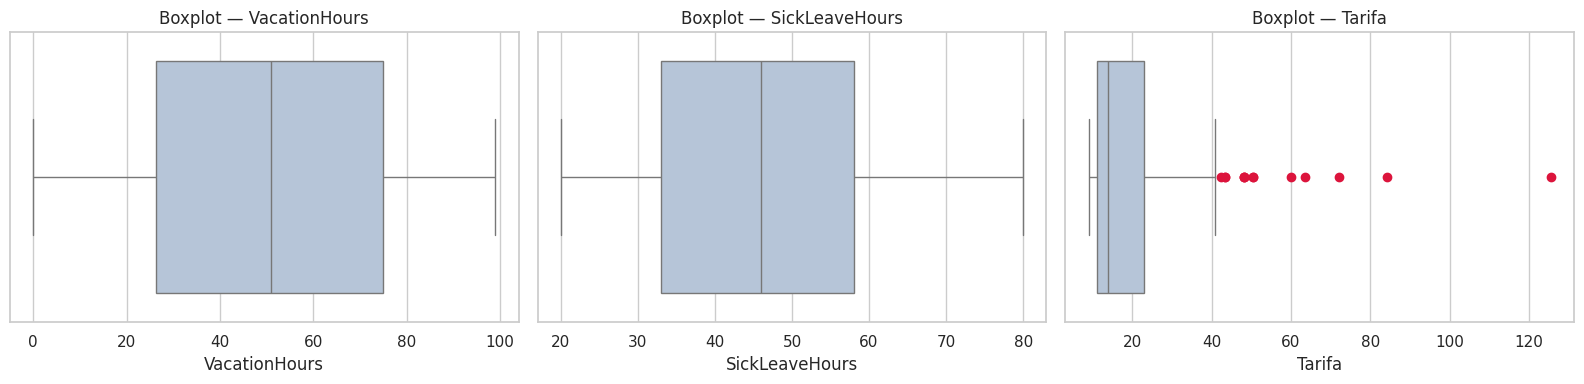

In [13]:
resumen_iqr = []
mascaras = {}
for col in num_cols:
    q1, q3 = dataset[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mascara = (dataset[col] < lim_inf) | (dataset[col] > lim_sup)
    mascaras[col] = mascara
    resumen_iqr.append({"Variable": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                        "Límite inferior": lim_inf, "Límite superior": lim_sup,
                        "Outliers": int(mascara.sum()), "% outliers": mascara.mean() * 100})
resumen_iqr = pd.DataFrame(resumen_iqr).set_index("Variable")
display(resumen_iqr)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=dataset[col], ax=ax, color="lightsteelblue", flierprops={"markerfacecolor": "crimson", "markeredgecolor": "crimson"})
    ax.set_title(f"Boxplot — {col}")
plt.tight_layout()
plt.show()

In [14]:
# ¿Quiénes son los outliers de Tarifa?
out_tarifa = (dataset.loc[mascaras["Tarifa"], ["BusinessEntityID", "JobTitle", "Departamento", "Turno", "Tarifa"]]
              .sort_values("Tarifa", ascending=False))
print(f"Outliers de Tarifa: {len(out_tarifa)} empleados")
display(out_tarifa)

Outliers de Tarifa: 13 empleados


,BusinessEntityID,JobTitle,Departamento,Turno,Tarifa
0,1,Chief Executive Officer,Executive,Day,125.50
24,25,Vice President of Production,Production,Day,84.13
272,273,Vice President of Sales,Sales,Day,72.12
1,2,Vice President of Engineering,Engineering,Day,63.46
233,234,Chief Financial Officer,Executive,Day,60.10
6,7,Research and Development Manager,Research and Development,Day,50.48
262,263,Information Services Manager,Information Services,Day,50.48
284,285,Pacific Sales Manager,Sales,Day,48.10
273,274,North American Sales Manager,Sales,Day,48.10
286,287,European Sales Manager,Sales,Day,48.10


### 2.D Medidas de dispersión (rango, varianza, desviación estándar, CV)

In [15]:
dispersion = pd.DataFrame({
    "Mínimo": dataset[num_cols].min(),
    "Máximo": dataset[num_cols].max(),
    "Rango": dataset[num_cols].max() - dataset[num_cols].min(),
    "Varianza": dataset[num_cols].var(),
    "Desv. estándar": dataset[num_cols].std(),
    "CV (%)": dataset[num_cols].std() / dataset[num_cols].mean() * 100,
    "IQR": dataset[num_cols].quantile(0.75) - dataset[num_cols].quantile(0.25),
})
display(dispersion)

,Mínimo,Máximo,Rango,Varianza,Desv. estándar,CV (%),IQR
VacationHours,0.00,99.00,99.00,828.65,28.79,56.87,48.75
SickLeaveHours,20.00,80.00,60.00,211.42,14.54,32.09,25.00
Tarifa,9.00,125.50,116.50,151.06,12.29,67.57,12.08


### Conclusiones 2 — Análisis descriptivo

**Variables categóricas (2.A)**
- Producción concentra **179 de 290 empleados (61.7 %)**; el grupo *Manufacturing* llega al 63.8 %. Hay 16 departamentos pero 14 tienen 12 empleados o menos.
- `JobTitle` es muy atomizado: 67 cargos, 28 con un solo empleado. Los más frecuentes son los *Production Technician* (WC30–WC60, 22–26 empleados cada uno).
- El turno **Day** reúne al 60.7 % de la plantilla (Evening 21.4 %, Night 17.9 %). El 71 % son hombres, el estado civil está equilibrado (50.3 % casados) y solo el 17.9 % tiene salario fijo (`SalariedFlag`).

**Tendencia central (2.B)**
- `VacationHours` (media 50.6, mediana 51) y `SickLeaveHours` (media 45.3, mediana 46) son **simétricas** (asimetría ≈ −0.07): media y mediana casi coinciden y el histograma es plano/amplio, sin un valor dominante.
- `Tarifa` es **fuertemente asimétrica a la derecha** (asimetría 3.92): media 18.19 > mediana 14.00 > moda 9.50. La media está inflada por pocos cargos directivos, así que **la mediana representa mejor al empleado típico**.

**Separatrices y outliers IQR (2.C)**
- `Tarifa`: Q1 = 11.00, Q3 = 23.08, IQR = 12.08, límite superior = 41.19. Hay **13 outliers (4.5 %)**, todos por arriba y todos del turno Day: directivos y gerentes (CEO 125.50, VP de Producción 84.13, VP de Ventas 72.12, etc.).
- `VacationHours` y `SickLeaveHours`: **0 outliers**. Los valores extremos de `Tarifa` son legítimos (roles ejecutivos), por lo que **no deben eliminarse**; conviene usar mediana o análisis separado por nivel jerárquico.

**Dispersión (2.D)**
- Desviación estándar: `VacationHours` 28.8 (varianza 828.7), `SickLeaveHours` 14.5 (211.4), `Tarifa` 12.3 (151.1).
- En términos relativos (CV), `Tarifa` es la más dispersa (**67.6 %**), seguida de `VacationHours` (56.9 %) y `SickLeaveHours` (32.1 %). Aunque la varianza de vacaciones es mayor en valor absoluto, esto se debe a la escala (0–99 horas), no a una mayor heterogeneidad que la tarifa.

**Conclusión:** la plantilla es mayoritariamente operativa, diurna y de producción. Las horas de ausencia se comportan de forma regular, mientras que la compensación está muy sesgada y condicionada por unos pocos cargos de alta dirección.

## 3. Análisis por segmentos

La variable de interés es `Tarifa` (pago por hora), acompañada de `VacationHours` y `SickLeaveHours`. Como `JobTitle` tiene muchos valores y varios segmentos son muy pequeños, **cada tabla incluye el número de empleados (`n`)**: un promedio con n = 1 o 2 no es concluyente.

In [16]:
def resumen_segmento(col, minimo_n=1):
    g = dataset.groupby(col).agg(
        n=("BusinessEntityID", "count"),
        Tarifa_media=("Tarifa", "mean"),
        Tarifa_mediana=("Tarifa", "median"),
        Tarifa_std=("Tarifa", "std"),
        Tarifa_min=("Tarifa", "min"),
        Tarifa_max=("Tarifa", "max"),
        Vacaciones_media=("VacationHours", "mean"),
        Enfermedad_media=("SickLeaveHours", "mean"),
    )
    g["% del total"] = g["n"] / g["n"].sum() * 100
    return g[g["n"] >= minimo_n].sort_values("Tarifa_media", ascending=False)

def boxplot_segmento(col, orden, titulo, alto=6):
    plt.figure(figsize=(11, alto))
    sns.boxplot(data=dataset, y=col, x="Tarifa", order=orden, hue=col, legend=False, palette="pastel", orient="h")
    plt.title(titulo)
    plt.xlabel("Tarifa (por hora)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

### 3.A Segmentación por cargo (`JobTitle`)

In [17]:
seg_job = resumen_segmento("JobTitle")
print(f"{len(seg_job)} cargos distintos | {int((seg_job['n'] == 1).sum())} cargos con un solo empleado\n")

print("Top 10 cargos con mayor tarifa media:")
display(seg_job.head(10))
print("Top 10 cargos con menor tarifa media:")
display(seg_job.tail(10))
print("Top 10 cargos con más empleados:")
display(seg_job.sort_values("n", ascending=False).head(10))

67 cargos distintos | 28 cargos con un solo empleado

Top 10 cargos con mayor tarifa media:


,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
JobTitle,,,,,,,,,
Chief Executive Officer,1,125.50,125.50,NaN,125.50,125.50,99.00,69.00,0.34
Vice President of Production,1,84.13,84.13,NaN,84.13,84.13,64.00,52.00,0.34
Vice President of Sales,1,72.12,72.12,NaN,72.12,72.12,10.00,25.00,0.34
Vice President of Engineering,1,63.46,63.46,NaN,63.46,63.46,1.00,20.00,0.34
Chief Financial Officer,1,60.10,60.10,NaN,60.10,60.10,0.00,20.00,0.34
Information Services Manager,1,50.48,50.48,NaN,50.48,50.48,65.00,52.00,0.34
Pacific Sales Manager,1,48.10,48.10,NaN,48.10,48.10,20.00,30.00,0.34
North American Sales Manager,1,48.10,48.10,NaN,48.10,48.10,14.00,27.00,0.34
European Sales Manager,1,48.10,48.10,NaN,48.10,48.10,21.00,30.00,0.34


Top 10 cargos con menor tarifa media:


,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
JobTitle,,,,,,,,,
Production Technician - WC60,26,12.45,12.45,0.00,12.45,12.45,26.50,33.00,8.97
Production Technician - WC50,26,11.00,11.00,0.00,11.00,11.00,46.65,43.08,8.97
Quality Assurance Technician,4,10.58,10.58,0.00,10.58,10.58,83.50,61.50,1.38
Document Control Assistant,2,10.25,10.25,0.00,10.25,10.25,78.50,59.00,0.69
Production Technician - WC45,15,10.00,10.00,0.00,10.00,10.00,80.00,59.73,5.17
Facilities Administrative Assistant,1,9.75,9.75,NaN,9.75,9.75,87.00,63.00,0.34
Shipping and Receiving Clerk,2,9.50,9.50,0.00,9.50,9.50,94.50,67.00,0.69
Production Technician - WC30,25,9.50,9.50,0.00,9.50,9.50,34.00,36.76,8.62
Janitor,4,9.25,9.25,0.00,9.25,9.25,89.50,64.50,1.38


Top 10 cargos con más empleados:


,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
JobTitle,,,,,,,,,
Production Technician - WC40,26,15.00,15.00,0.00,15.00,15.00,59.50,49.50,8.97
Production Technician - WC50,26,11.00,11.00,0.00,11.00,11.00,46.65,43.08,8.97
Production Technician - WC60,26,12.45,12.45,0.00,12.45,12.45,26.50,33.00,8.97
Production Technician - WC30,25,9.50,9.50,0.00,9.50,9.50,34.00,36.76,8.62
Production Technician - WC20,22,14.00,14.00,0.00,14.00,14.00,10.50,25.00,7.59
Production Technician - WC10,17,13.45,13.45,0.00,13.45,13.45,91.00,65.24,5.86
Production Technician - WC45,15,10.00,10.00,0.00,10.00,10.00,80.00,59.73,5.17
Sales Representative,14,23.08,23.08,0.00,23.08,23.08,31.00,35.21,4.83
Buyer,9,18.27,18.27,0.00,18.27,18.27,56.00,47.78,3.10


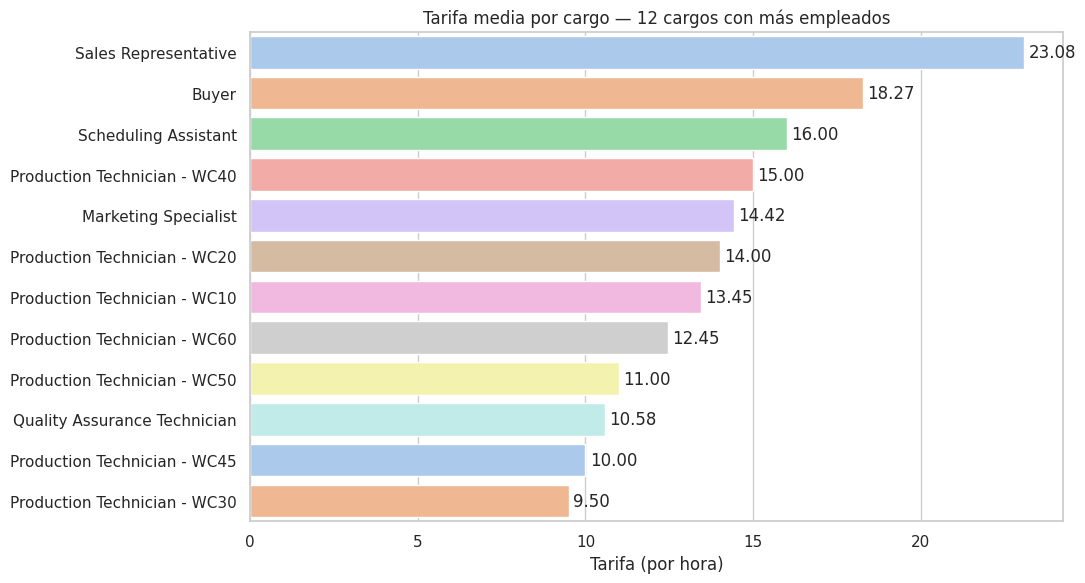

Cargos con 2+ empleados: 39 | con tarifa idéntica para todos (std = 0): 37


In [18]:
# Los cargos más numerosos tienen tarifa casi constante (std = 0), por lo que un boxplot sería una línea: se usa barras
top12 = dataset["JobTitle"].value_counts().head(12).index
datos = (dataset[dataset["JobTitle"].isin(top12)].groupby("JobTitle")["Tarifa"].agg(["mean", "count"])
         .sort_values("mean", ascending=False))
plt.figure(figsize=(11, 6))
ax = sns.barplot(x=datos["mean"], y=datos.index, hue=datos.index, legend=False, palette="pastel")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", padding=3)
plt.title("Tarifa media por cargo — 12 cargos con más empleados")
plt.xlabel("Tarifa (por hora)"); plt.ylabel("")
plt.tight_layout(); plt.show()

# ¿La tarifa depende del cargo? Variabilidad de Tarifa dentro de cada cargo con 2+ empleados
multi = dataset.groupby("JobTitle")["Tarifa"].agg(n="count", std="std").query("n >= 2")
print(f"Cargos con 2+ empleados: {len(multi)} | con tarifa idéntica para todos (std = 0): {int((multi['std'] == 0).sum())}")

### 3.B Segmentación por departamento (`Departamento`)

,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
Departamento,,,,,,,,,
Executive,2,92.80,92.80,46.25,60.10,125.50,49.50,44.50,0.69
Research and Development,4,43.67,41.67,4.60,40.87,50.48,50.50,54.00,1.38
Engineering,6,40.14,34.38,12.14,32.69,63.46,3.50,21.50,2.07
Information Services,10,34.16,32.45,7.62,27.40,50.48,69.50,54.50,3.45
Sales,18,29.97,23.08,14.20,23.08,72.12,27.72,33.61,6.21
Tool Design,4,27.17,26.92,2.54,25.00,29.85,18.00,37.75,1.38
Finance,10,23.94,19.00,9.03,13.46,43.27,59.50,49.50,3.45
Production Control,6,18.68,16.00,4.16,16.00,24.52,45.50,42.50,2.07
Purchasing,12,18.33,18.27,4.25,12.75,30.00,54.50,47.00,4.14


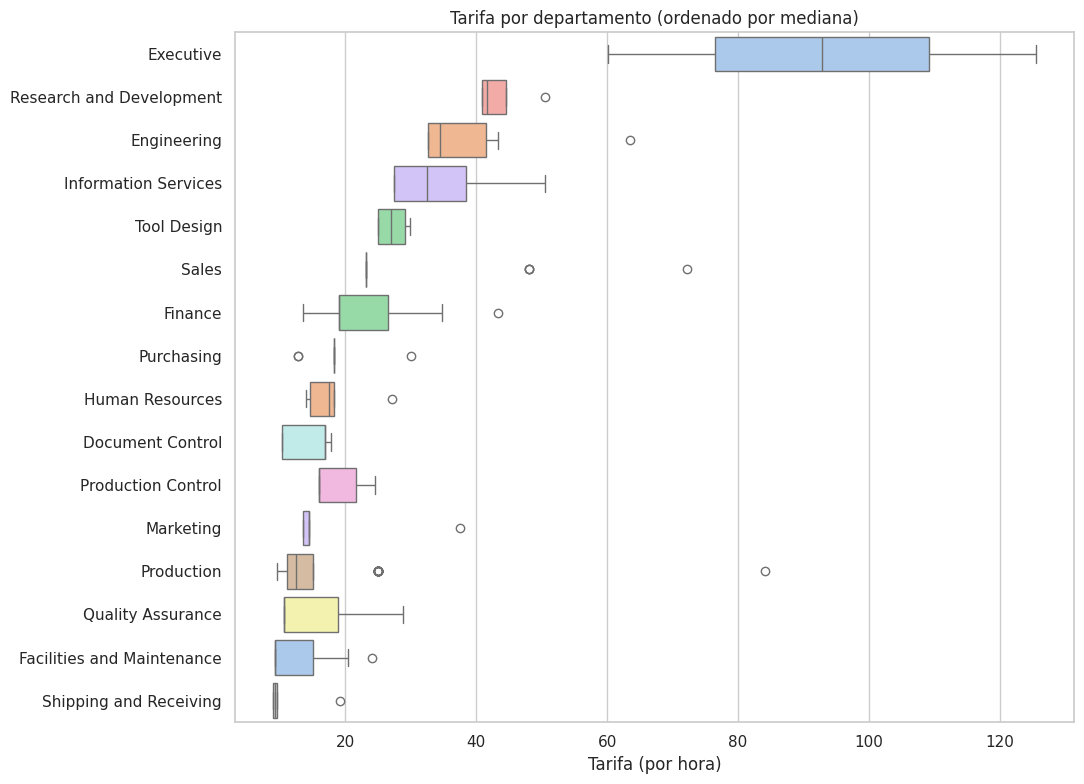

In [19]:
seg_dep = resumen_segmento("Departamento")
display(seg_dep)
boxplot_segmento("Departamento", seg_dep.sort_values("Tarifa_mediana", ascending=False).index,
                 "Tarifa por departamento (ordenado por mediana)", alto=8)

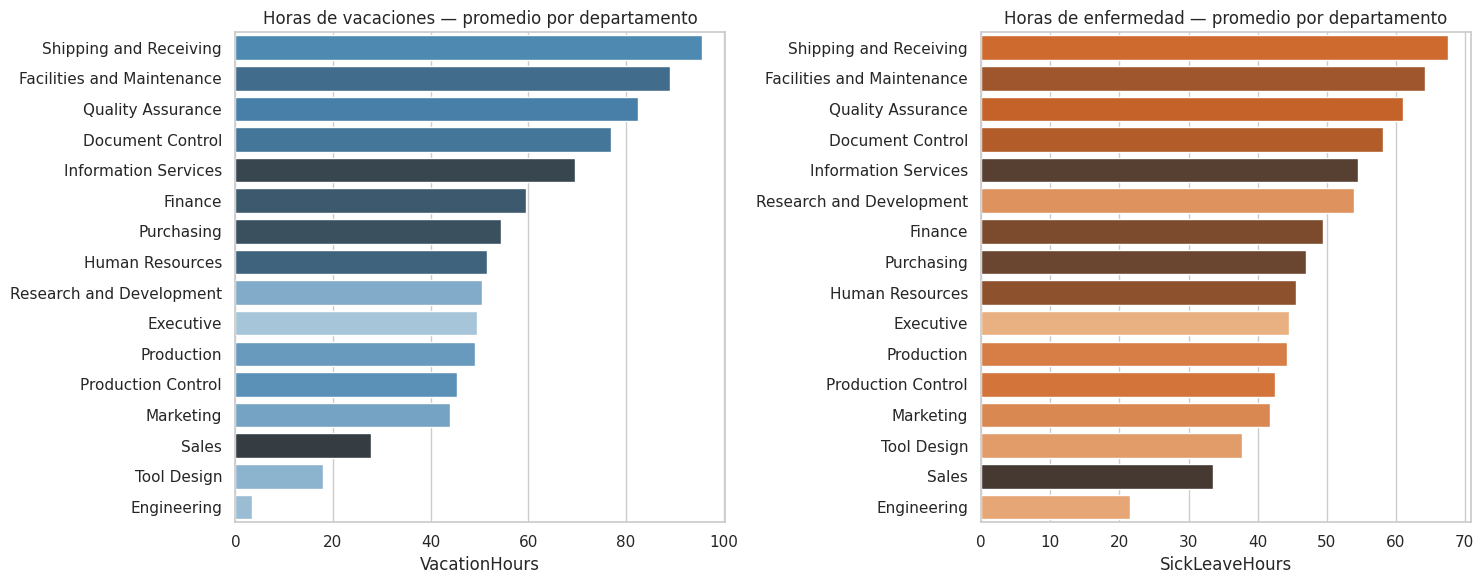

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
orden_dep = seg_dep.sort_values("Vacaciones_media", ascending=False).index
sns.barplot(data=dataset, y="Departamento", x="VacationHours", order=orden_dep, hue="Departamento", legend=False,
            palette="Blues_d", errorbar=None, ax=axes[0])
axes[0].set_title("Horas de vacaciones — promedio por departamento")
orden_enf = seg_dep.sort_values("Enfermedad_media", ascending=False).index
sns.barplot(data=dataset, y="Departamento", x="SickLeaveHours", order=orden_enf, hue="Departamento", legend=False,
            palette="Oranges_d", errorbar=None, ax=axes[1])
axes[1].set_title("Horas de enfermedad — promedio por departamento")
for ax in axes: ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 3.C Segmentación por turno (`Turno`)

,n,Tarifa_media,Tarifa_mediana,Tarifa_std,Tarifa_min,Tarifa_max,Vacaciones_media,Enfermedad_media,% del total
Turno,,,,,,,,,
Day,176,20.94,15.00,14.63,9.00,125.50,49.26,44.79,60.69
Evening,62,14.00,12.45,5.13,9.00,32.45,49.47,44.48,21.38
Night,52,13.86,12.45,4.89,9.00,25.00,56.58,48.04,17.93


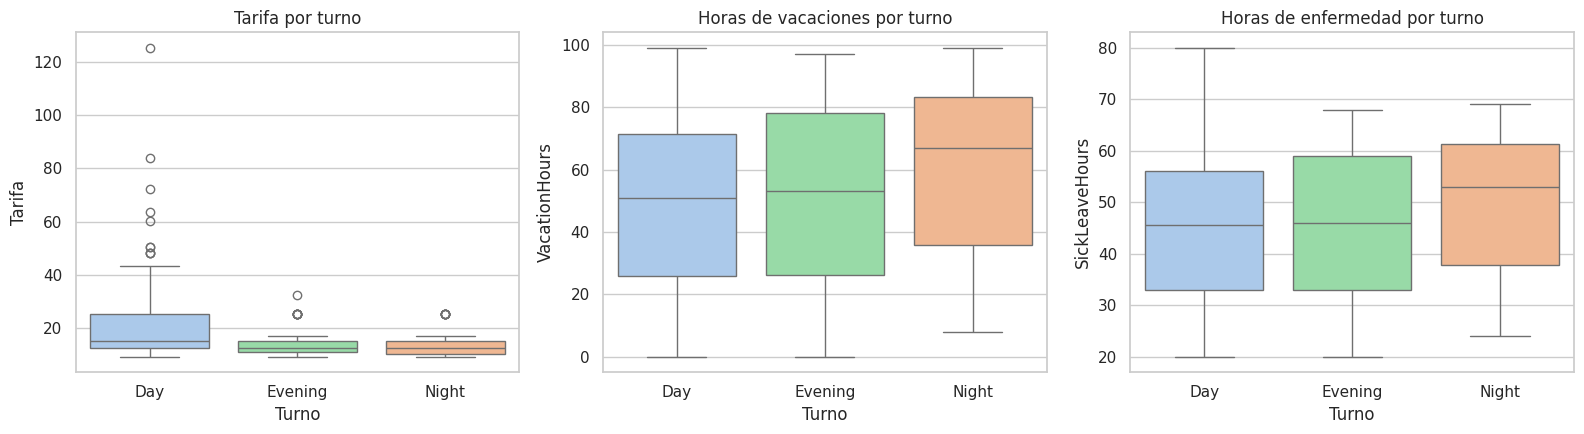

In [21]:
seg_turno = resumen_segmento("Turno")
display(seg_turno)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
orden_t = ["Day", "Evening", "Night"]
sns.boxplot(data=dataset, x="Turno", y="Tarifa", order=orden_t, hue="Turno", legend=False, palette="pastel", ax=axes[0])
axes[0].set_title("Tarifa por turno")
sns.boxplot(data=dataset, x="Turno", y="VacationHours", order=orden_t, hue="Turno", legend=False, palette="pastel", ax=axes[1])
axes[1].set_title("Horas de vacaciones por turno")
sns.boxplot(data=dataset, x="Turno", y="SickLeaveHours", order=orden_t, hue="Turno", legend=False, palette="pastel", ax=axes[2])
axes[2].set_title("Horas de enfermedad por turno")
plt.tight_layout(); plt.show()

In [22]:
# El turno diurno incluye los cargos administrativos mejor pagados: se compara también solo el departamento de Producción
prod = dataset[dataset["Departamento"] == "Production"]
print("Tarifa por turno — solo departamento de Producción:")
display(prod.groupby("Turno")["Tarifa"].agg(n="count", media="mean", mediana="median", std="std"))

Tarifa por turno — solo departamento de Producción:


,n,media,mediana,std
Turno,,,,
Day,79,14.28,12.45,8.95
Evening,54,13.98,12.95,4.66
Night,46,14.13,12.95,5.00


### 3.D Cruce `Departamento × Turno` y síntesis de segmentos

Turno,Day,Evening,Night,Total
Departamento,,,,
Document Control,3,1,1,5
Engineering,6,0,0,6
Executive,2,0,0,2
Facilities and Maintenance,3,2,2,7
Finance,10,0,0,10
Human Resources,6,0,0,6
Information Services,9,1,0,10
Marketing,9,0,0,9
Production,79,54,46,179


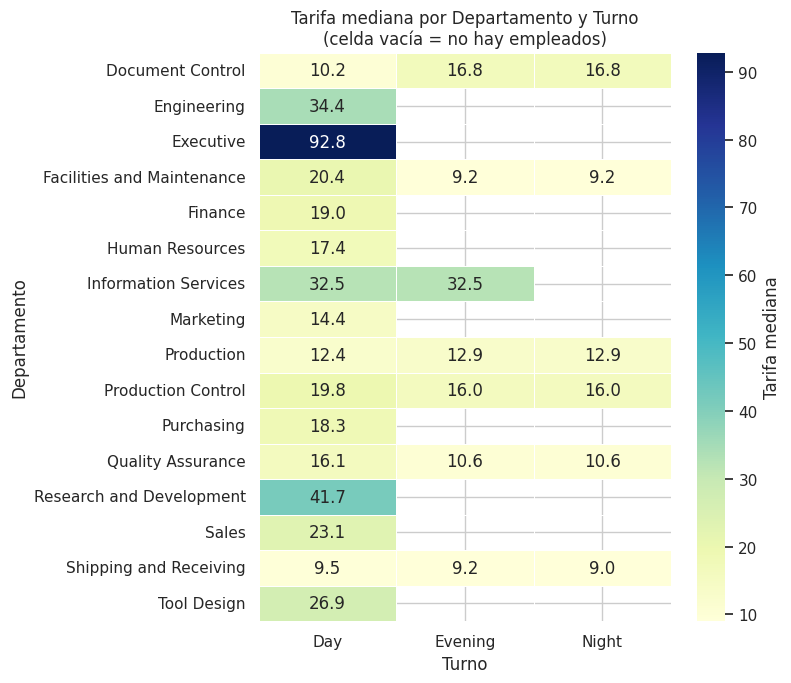

In [23]:
frecuencias = pd.crosstab(dataset["Departamento"], dataset["Turno"], margins=True, margins_name="Total")
display(frecuencias)

tabla_tarifa = dataset.pivot_table(index="Departamento", columns="Turno", values="Tarifa", aggfunc="median")
plt.figure(figsize=(8, 7))
sns.heatmap(tabla_tarifa, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "Tarifa mediana"})
plt.title("Tarifa mediana por Departamento y Turno\n(celda vacía = no hay empleados)")
plt.tight_layout(); plt.show()

In [24]:
# Segmentación por rol: asalariados vs. por hora y por género dentro de la tarifa
display(dataset.groupby("SalariedFlag")["Tarifa"].agg(n="count", media="mean", mediana="median"))
display(dataset.groupby("Gender")["Tarifa"].agg(n="count", media="mean", mediana="median"))

,n,media,mediana
SalariedFlag,,,
False,238,14.32,13.45
True,52,35.88,28.12


,n,media,mediana
Gender,,,
F,84,19.23,14.00
M,206,17.76,14.00


### Conclusiones 3 — Análisis por segmentos

**Por cargo (3.A)**
- La `Tarifa` está determinada casi por completo por el cargo: de los 39 cargos con 2 o más empleados, **37 tienen exactamente la misma tarifa para todos** (std = 0). Por eso los boxplots por cargo serían degenerados y se usaron barras.
- Los cargos mejor pagados son de dirección (CEO 125.50, VP de Producción 84.13, VP de Ventas 72.12) y todos tienen n = 1: son casos individuales, no un patrón estadístico. Los menos pagados son operativos (*Stocker* 9.00, *Janitor* 9.25, *Production Technician WC30* 9.50).
- Entre los técnicos de producción hay diferencias entre estaciones de trabajo (WC30 = 9.50 vs. WC40 = 15.00) con un n comparable (≈ 25), lo que sugiere una escala salarial por estación.

**Por departamento (3.B)**
- Mayor tarifa media: Executive (92.80, n = 2), Research and Development (43.67, n = 4), Engineering (40.14, n = 6) e Information Services (34.16, n = 10). Los más bajos: Shipping and Receiving (10.87), Facilities and Maintenance (13.03) y **Production (14.15, n = 179)**.
- Dentro de varios departamentos la media supera a la mediana (Sales: 29.97 vs 23.08), señal de que unos pocos gerentes elevan el promedio.
- El departamento de Engineering destaca por tener muy pocas horas de vacaciones acumuladas (≈ 3.5 en promedio), un punto a revisar desde RR. HH.

**Por turno (3.C)**
- Day tiene tarifa media de 20.94 frente a 14.00 (Evening) y 13.86 (Night). Sin embargo, la **mediana** es 15.00 vs 12.45 y 12.45, y la diferencia se explica por composición: todos los cargos administrativos y directivos trabajan en turno Day.
- Comparando **solo Producción**, los turnos son equivalentes (medias 14.28, 13.98 y 14.13). **No hay evidencia de pago diferencial por turno nocturno o vespertino.**
- Night muestra algo más de horas de vacaciones (56.6) y de enfermedad (48.0) que Day (49.3 y 44.8); es una diferencia leve que conviene validar con más datos.

**Cruce y otros segmentos (3.D)**
- Solo 6 de los 16 departamentos tienen presencia en los tres turnos; los turnos Evening y Night están dominados por Producción (54 y 46 de 62 y 52 empleados). Los demás departamentos operan casi exclusivamente en turno Day.
- Los empleados con **salario fijo** ganan en promedio 35.88 frente a 14.32 de los pagados por hora. Por género, la media es 19.23 (F) vs 17.76 (M), pero la **mediana es idéntica (14.00)**: la diferencia de media se debe a pocos cargos y no a un patrón general.

**Conclusión:** la compensación depende del cargo y del nivel jerárquico, no del turno. Los análisis comparativos deben controlar por departamento/cargo y considerar el tamaño de cada segmento (muchos tienen n < 10).

## Conclusión general del EDA


- El dataset es limpio (sin nulos, duplicados ni incoherencias) y listo para análisis posteriores.
- `VacationHours` y `SickLeaveHours` son simétricas y sin outliers; `Tarifa` es asimétrica (skew 3.92) con 13 outliers legítimos que corresponden a cargos directivos.
- La estructura organizacional está muy concentrada: Producción, turno Day y técnicos de producción dominan la plantilla.
- La `Tarifa` se explica principalmente por el **cargo** (37 de 39 cargos con 2+ empleados tienen tarifa única) y el tipo de contratación (salariados vs. por hora), no por el turno ni por el género.
- **Limitaciones:** muchos segmentos con n muy pequeño (28 cargos con un solo empleado); sin diferenciación por antigüedad o edad. Próximos pasos sugeridos: analizar antigüedad (`HireDate`) y edad (`BirthDate`) frente a `Tarifa` y ausentismo.